# Lineup chemistry and player compatibility
**Eclipse Analytics | NBA research | Topic B**

### Research question
Do player **roles** and **pair-level co-play history** help explain five-player lineup
net rating beyond the average talent of the five players?

### What this notebook adds to the team's work
It builds on Eliot's collection (`data_gather_eliot.ipynb`,
`data_gathering_five_seasons.ipynb`) and his K-means archetypes
(`data_exploration_five_seasons.ipynb`). New here:

1. A **live, verified** investigation of the two endpoints I was assigned —
   `PlayerVsPlayer` and `LeagueDashLineups` — including what they do *not* measure.
2. **Measured two-man lineup data** (`LeagueDashLineups(group_quantity=2)`), which gives
   real on-court ratings for player pairs instead of only estimates.
3. A **reliability analysis** quantifying how much of a lineup's net rating is signal
   versus sampling noise — this turned out to govern every other conclusion.
4. Pair co-play proxies that are **validated against** the measured two-man ratings.
5. Archetype-composition analysis using Eliot's clusters, with team strength controlled.
6. A baseline predictive model with a **leakage-free temporal holdout**, plus a direct
   demonstration of how much leakage inflates the apparent result.

### Vocabulary (used precisely throughout)
| Term | Meaning |
|---|---|
| **observed lineup performance** | `NET_RATING` the NBA measured for a specific five-man group. A description of what happened. |
| **measured pair performance** | `NET_RATING` for a two-man group, straight from the API. Also observed, but on a much larger sample. |
| **pair co-play proxy** | Possession-weighted average of the net ratings of the five-man lineups a pair appears in. **An estimate, not a chemistry score.** |

> **None of these is a chemistry score.** Every number here is confounded by the other
> three teammates, the opponents, coaching, and how the coach chose to use the lineup.
> Nothing in this notebook supports a causal claim.

## 0. Setup
Run from the repository root. Reusable transformations live in `lineup_chemistry.py` and are unit tested in `tests/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the repo root importable whether the kernel starts here or in a subdir.
ROOT = Path.cwd() if (Path.cwd() / "lineup_chemistry.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import lineup_chemistry as lc

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
DATA = lc.data_dir(ROOT)
print("data directory:", DATA)
print("seasons:", lc.SEASONS)

data directory: /Users/atharvabang/eclipse_nba_chemistry/basketball_data
seasons: ['2021-22', '2022-23', '2023-24', '2024-25', '2025-26']


## 1. Audit the committed data
Before building anything new, verify what is actually in the repository rather than
trusting earlier reported numbers.

In [2]:
lineups = pd.read_csv(DATA / "lineups_five_seasons.csv")
players = pd.read_csv(DATA / "player_stats_five_seasons.csv")
clusters = pd.read_csv(DATA / "player_clusters_five_seasons.csv")

print(f"lineups_five_seasons        {lineups.shape[0]:>6,} rows x {lineups.shape[1]} cols")
print(f"player_stats_five_seasons   {players.shape[0]:>6,} rows x {players.shape[1]} cols")
print(f"player_clusters_five_seasons{clusters.shape[0]:>6,} rows x {clusters.shape[1]} cols")
print()
print("lineups per season:", lineups.SEASON.value_counts().sort_index().to_dict())
print("players per season:", players.SEASON.value_counts().sort_index().to_dict())
print()
print("duplicate (GROUP_ID, SEASON):", lineups.duplicated(["GROUP_ID", "SEASON"]).sum())
print("duplicate (PLAYER_ID, SEASON):", players.duplicated(["PLAYER_ID", "SEASON"]).sum())
print("NET_RATING vs OFF-DEF, max abs difference:",
      (lineups.NET_RATING - (lineups.OFF_RATING - lineups.DEF_RATING)).abs().max())

lineups_five_seasons        10,000 rows x 51 cols
player_stats_five_seasons    2,867 rows x 126 cols
player_clusters_five_seasons 2,025 rows x 131 cols

lineups per season: {'2021-22': 2000, '2022-23': 2000, '2023-24': 2000, '2024-25': 2000, '2025-26': 2000}
players per season: {'2021-22': 605, '2022-23': 539, '2023-24': 572, '2024-25': 569, '2025-26': 582}

duplicate (GROUP_ID, SEASON): 0
duplicate (PLAYER_ID, SEASON): 0
NET_RATING vs OFF-DEF, max abs difference: 0.10000000000002274


### 1.1 `GROUP_ID` parsing and the player join
`LeagueDashLineups` encodes the five members as `"-201145-203115-203932-203999-1628420-"`.
Parsing those IDs is safer than matching the abbreviated names in `GROUP_NAME`
("J. Green" is ambiguous).

In [3]:
lineups = lc.add_player_ids(lineups)

print("groups parsing to exactly 5 IDs:      ", f"{(lineups.N_PLAYERS == 5).sum():,} / {len(lineups):,}")
print("groups with 5 *distinct* IDs:         ", f"{(lineups.N_UNIQUE_PLAYERS == 5).sum():,} / {len(lineups):,}")

known_players = set(zip(players.PLAYER_ID, players.SEASON))
member_rows = [(pid, r.SEASON) for r in lineups.itertuples(index=False) for pid in r.PLAYER_IDS]
matched = sum(k in known_players for k in member_rows)
print("lineup members found in player stats: ", f"{matched:,} / {len(member_rows):,}"
      f"  ({100 * matched / len(member_rows):.1f}%)")

labelled = set(zip(clusters.PLAYER_ID, clusters.SEASON))
cov = sum(k in labelled for k in member_rows)
print("lineup members with a cluster label:  ", f"{cov:,} / {len(member_rows):,}"
      f"  ({100 * cov / len(member_rows):.1f}%)")
print()
print("Eliot's archetypes (from cluster_profiles_five_seasons.csv):")
for k, v in lc.CLUSTER_LABELS.items():
    print(f"  cluster {k}: {v}")

groups parsing to exactly 5 IDs:       10,000 / 10,000
groups with 5 *distinct* IDs:          10,000 / 10,000
lineup members found in player stats:  50,000 / 50,000  (100.0%)
lineup members with a cluster label:   48,743 / 50,000  (97.5%)

Eliot's archetypes (from cluster_profiles_five_seasons.csv):
  cluster 0: Interior finisher
  cluster 1: Perimeter role player
  cluster 2: High-usage creator


### 1.2 The single most important property of this dataset
`LeagueDashLineups` returns **at most 2,000 rows per request**. That is a server-side cap,
not something Eliot's code chose, and it means the five-man data is the *most-used*
2,000 lineups per season, sorted by minutes. Two consequences:

* **Selection bias** — rarely-used lineups are absent, so this is not a census of lineups.
* **Tiny samples** — even inside the top 2,000, the median lineup plays very few possessions.

In [4]:
print("sorted by MIN descending:", lineups.groupby("SEASON").MIN.apply(lambda s: s.is_monotonic_decreasing).to_dict())
print()
print(lineups[["MIN", "POSS", "GP", "NET_RATING"]].describe().round(2).to_string())
print()
for t in (50, 100, 200, 500, 1000):
    n = (lineups.POSS >= t).sum()
    print(f"  lineups with POSS >= {t:>4}: {n:>5,}  ({100 * n / len(lineups):4.1f}%)")

sorted by MIN descending: {'2021-22': True, '2022-23': True, '2023-24': True, '2024-25': True, '2025-26': True}

            MIN      POSS        GP  NET_RATING
count  10000.00  10000.00  10000.00    10000.00
mean      34.81     74.11      7.06        1.80
std       53.25    111.94      5.53       26.71
min       12.00     20.00      1.00      -94.40
25%       15.00     32.00      4.00      -15.20
50%       21.00     44.00      6.00        2.10
75%       33.00     70.00      9.00       18.60
max      958.00   1952.00     63.00      109.10

  lineups with POSS >=   50: 4,215  (42.1%)
  lineups with POSS >=  100: 1,492  (14.9%)
  lineups with POSS >=  200:   537  ( 5.4%)
  lineups with POSS >=  500:   129  ( 1.3%)
  lineups with POSS >= 1000:    28  ( 0.3%)


## 2. Endpoint A — `PlayerVsPlayer`
**Verified live** against `stats.nba.com` with `nba_api` 1.12.0.

The endpoint returns **10 result sets**. The one that matters for compatibility work is
`OnOffCourt`: it takes `player_id`'s own box score and splits it by whether
`vs_player_id` was **on or off the court**.

Two things to be clear about:

* It is **not a chemistry score**, and not symmetric — the output describes
  `player_id`'s production, not a joint pair measurement. Swapping the two IDs gives a
  different table.
* Whether it measures *teammate compatibility* or an *opponent matchup* depends entirely
  on whom you pass. Same mechanic, different meaning:
  * `vs_player_id` = **teammate** -> "On" is the minutes they shared -> teammate on/off.
  * `vs_player_id` = **opponent** -> "On" is head-to-head floor time -> matchup split.

One useful discovery: the endpoint accepts `measure_type_detailed_defense="Advanced"`,
which returns `OFF_RATING` / `DEF_RATING` / `NET_RATING` / `POSS` for each split rather
than only Base box-score counts. That makes a genuine **on/off rating differential**
available per pair.

In [5]:
# Live request. Set RUN_LIVE_API = True to re-run against stats.nba.com.
# The committed CSV below was produced by scripts/collect_pair_data.py, which
# made exactly this call.
RUN_LIVE_API = False

if RUN_LIVE_API:
    from nba_api.stats.endpoints import playervsplayer

    resp = playervsplayer.PlayerVsPlayer(
        player_id=2544,        # LeBron James
        vs_player_id=1629637,  # Jaxson Hayes - a teammate, so this is a teammate split
        season="2025-26",
        season_type_playoffs="Regular Season",
        measure_type_detailed_defense="Advanced",
        per_mode_detailed="Per100Possessions",
        timeout=60,
    )
    for name, frame in zip([rs["name"] for rs in resp.get_dict()["resultSets"]],
                           resp.get_data_frames()):
        print(f"{name:<22} shape={frame.shape}")
    onoff_live = resp.get_data_frames()[1]
    display(onoff_live)
else:
    print("RUN_LIVE_API is False - showing the stored response instead.")

RUN_LIVE_API is False - showing the stored response instead.


In [6]:
pvp = pd.read_csv(DATA / "player_vs_player_onoff_2025-26.csv")
print(f"stored PlayerVsPlayer rows: {len(pvp)}  "
      f"({pvp.PAIR_GROUP_ID.nunique()} teammate pairs x On/Off)")

cols = ["PLAYER_NAME", "VS_PLAYER_NAME", "COURT_STATUS", "GP", "MIN", "POSS",
        "OFF_RATING", "DEF_RATING", "NET_RATING", "TS_PCT", "USG_PCT"]
display(pvp[cols].head(6))

stored PlayerVsPlayer rows: 30  (15 teammate pairs x On/Off)


,PLAYER_NAME,VS_PLAYER_NAME,COURT_STATUS,GP,MIN,POSS,OFF_RATING,DEF_RATING,NET_RATING,TS_PCT,USG_PCT
0,Kevin Durant,"Thompson, Amen",On,76,28.4,4458,117.0,111.6,5.4,0.648,0.252
1,Kevin Durant,"Thompson, Amen",Off,78,8.8,1462,112.2,107.1,5.1,0.622,0.282
2,Jabari Smith Jr.,"Thompson, Amen",On,75,28.4,4346,117.4,111.5,5.9,0.580,0.179
3,Jabari Smith Jr.,"Thompson, Amen",Off,77,7.5,1226,108.6,107.6,1.1,0.528,0.169
4,Kevin Durant,"Smith Jr., Jabari",On,74,27.5,4177,117.7,112.3,5.4,0.633,0.257
5,Kevin Durant,"Smith Jr., Jabari",Off,78,10.3,1706,113.8,107.6,6.1,0.659,0.270


### 2.1 Turning on/off splits into a per-pair differential
`NET_RATING(on) - NET_RATING(off)` is the natural summary. Note what it is **not**: the
"off" split pools every possession the player played without that teammate, including
games the teammate missed entirely, so the comparison is not against a fixed context.

In [7]:
wide = pvp.pivot_table(
    index=["PLAYER_NAME", "VS_PLAYER_NAME", "PAIR_GROUP_ID"],
    columns="COURT_STATUS",
    values=["NET_RATING", "MIN", "POSS", "TS_PCT", "USG_PCT"],
)
diff = pd.DataFrame({
    "NET_on": wide[("NET_RATING", "On")],
    "NET_off": wide[("NET_RATING", "Off")],
    "MIN_on": wide[("MIN", "On")],
    "MIN_off": wide[("MIN", "Off")],
    "TS_on": wide[("TS_PCT", "On")],
    "TS_off": wide[("TS_PCT", "Off")],
    "USG_on": wide[("USG_PCT", "On")],
    "USG_off": wide[("USG_PCT", "Off")],
}).reset_index()
diff["NET_DIFF"] = diff.NET_on - diff.NET_off
diff["USG_DIFF"] = diff.USG_on - diff.USG_off

display(diff.sort_values("NET_DIFF", ascending=False)
            [["PLAYER_NAME", "VS_PLAYER_NAME", "MIN_on", "MIN_off",
              "NET_on", "NET_off", "NET_DIFF", "USG_DIFF"]].round(2))

,PLAYER_NAME,VS_PLAYER_NAME,MIN_on,MIN_off,NET_on,NET_off,NET_DIFF,USG_DIFF
1,Alperen Sengun,"Thompson, Amen",28.3,5.9,5.3,-5.8,11.1,0.02
5,Jalen Johnson,"Daniels, Dyson",28.6,8.4,5.3,-2.7,8.0,0.00
6,Julius Randle,"DiVincenzo, Donte",23.4,9.7,5.9,-0.5,6.4,0.01
2,Deni Avdija,"Camara, Toumani",26.7,6.9,1.9,-3.2,5.1,-0.02
12,Rudy Gobert,"DiVincenzo, Donte",23.6,7.7,6.5,1.6,4.9,0.01
4,Jabari Smith Jr.,"Thompson, Amen",28.4,7.5,5.9,1.1,4.8,0.01
14,Wendell Carter Jr.,"Bane, Desmond",23.2,6.1,3.2,-0.8,4.0,0.01
11,Nickeil Alexander-Walker,"Johnson, Jalen",27.9,8.4,4.8,1.8,3.0,-0.03
13,Wendell Carter Jr.,"Banchero, Paolo",25.5,8.1,2.8,0.0,2.8,-0.01
0,Alperen Sengun,"Smith Jr., Jabari",25.9,9.0,3.3,2.7,0.6,0.00


**Verdict on `PlayerVsPlayer` for this project.** Useful but awkward as a primary source:

* It genuinely supports teammate on/off and opponent-matchup analysis, and with
  `measure_type="Advanced"` it gives rating differentials.
* But it is **one HTTP request per ordered pair**. Covering even the ~2,000 most-played
  pairs in a single season means thousands of requests, and the "off" baseline shifts
  from pair to pair.
* `LeagueDashLineups(group_quantity=2)` returns the same kind of information for
  **2,000 pairs in one request**, already possession-denominated and symmetric.

So I use `PlayerVsPlayer` for **targeted follow-up on specific pairs** (where the on/off
split and the usage shift are exactly what you want) and `LeagueDashLineups` for
**bulk pair data**. That is the opposite of how the task was originally framed, and it is
the main practical finding about this endpoint.

## 3. Endpoint B — `LeagueDashLineups`
Also **verified live**. Re-requesting the 2025-26 five-man data reproduced Eliot's
committed CSV exactly — same 2,000 `GROUP_ID`s, and zero difference in `MIN`, `POSS` and
`NET_RATING`. His collection is reproducible, so there is no reason to re-download it.

The parameter worth attention is **`group_quantity`**, which Eliot fixed at 5. Setting it
to 2 returns **measured two-man combination stats**: real `OFF_RATING` / `DEF_RATING` /
`NET_RATING` / `POSS` for pairs, not estimates. `scripts/collect_pair_data.py` collects
these for all five seasons into `lineups_pairs_*.csv`.

In [8]:
two_man = pd.read_csv(DATA / "lineups_pairs_five_seasons.csv")
print(f"two-man lineups: {two_man.shape[0]:,} rows x {two_man.shape[1]} cols "
      f"({two_man.SEASON.nunique()} seasons x 2,000 cap)")

compare = pd.DataFrame({
    "five-man (group_quantity=5)": lineups[["MIN", "POSS"]].median(),
    "two-man (group_quantity=2)": two_man[["MIN", "POSS"]].median(),
}).round(1)
compare.index = ["median MIN", "median POSS"]
display(compare)

print("\nTwo-man groups parsing to 2 distinct IDs:",
      f"{(lc.add_player_ids(two_man).N_UNIQUE_PLAYERS == 2).sum():,} / {len(two_man):,}")
print("\nSample of the most-played pairs in 2025-26:")
display(two_man[two_man.SEASON == "2025-26"]
        .nlargest(5, "MIN")[["GROUP_NAME", "TEAM_ABBREVIATION", "GP", "MIN", "POSS",
                             "OFF_RATING", "DEF_RATING", "NET_RATING"]])

two-man lineups: 10,000 rows x 51 cols (5 seasons x 2,000 cap)


,five-man (group_quantity=5),two-man (group_quantity=2)
median MIN,21.0,380.5
median POSS,44.0,806.0



Two-man groups parsing to 2 distinct IDs: 10,000 / 10,000

Sample of the most-played pairs in 2025-26:


,GROUP_NAME,TEAM_ABBREVIATION,GP,MIN,POSS,OFF_RATING,DEF_RATING,NET_RATING
8000,K. Durant - A. Thompson,HOU,76,2157.0,4458,117.0,111.6,5.4
8001,J. Smith Jr. - A. Thompson,HOU,75,2130.0,4346,117.4,111.5,5.9
8002,K. Durant - J. Smith Jr.,HOU,74,2034.0,4177,117.7,112.3,5.4
8003,A. Sengun - A. Thompson,HOU,70,1978.0,4084,117.6,112.3,5.3
8004,N. Alexander-Walker - J. Johnson,ATL,71,1978.0,4316,115.8,111.0,4.8


## 4. How much signal is there at all?
This section drove every later decision, so it comes before the analysis rather than
after it.

A lineup's net rating is an average over `POSS` possessions, so its sampling variance
shrinks roughly as `1 / POSS`. Across possession bins:

$$\mathrm{Var}(\text{observed} \mid POSS) = \underbrace{\mathrm{Var}(\text{true})}_{\text{real spread in lineup quality}} + \frac{k}{POSS}$$

Fitting that line against `1/POSS` separates real spread (the intercept) from noise
(the slope). The ratio `k / Var(true)` is the possession count at which an observation
deserves equal weight with the league prior.

In [9]:
rel5 = lc.estimate_reliability(lineups, value_col="NET_RATING", weight_col="POSS")
rel2 = lc.estimate_reliability(two_man, value_col="NET_RATING", weight_col="POSS")

summary = pd.DataFrame({
    "five-man lineups": [rel5["sd_true"], rel5["var_noise_coefficient"],
                         rel5["equal_weight_poss"], rel5["median_poss"],
                         rel5["reliability_at_median_poss"]],
    "two-man lineups": [rel2["sd_true"], rel2["var_noise_coefficient"],
                        rel2["equal_weight_poss"], rel2["median_poss"],
                        rel2["reliability_at_median_poss"]],
}, index=["SD of true quality (net rating pts)", "noise coefficient k",
          "possessions for equal weight with prior", "median possessions",
          "reliability at median possessions"]).round(3)
display(summary)

,five-man lineups,two-man lineups
SD of true quality (net rating pts),6.362,5.777
noise coefficient k,30015.271,27902.252
possessions for equal weight with prior,741.653,836.110
median possessions,44.000,806.000
reliability at median possessions,0.056,0.491


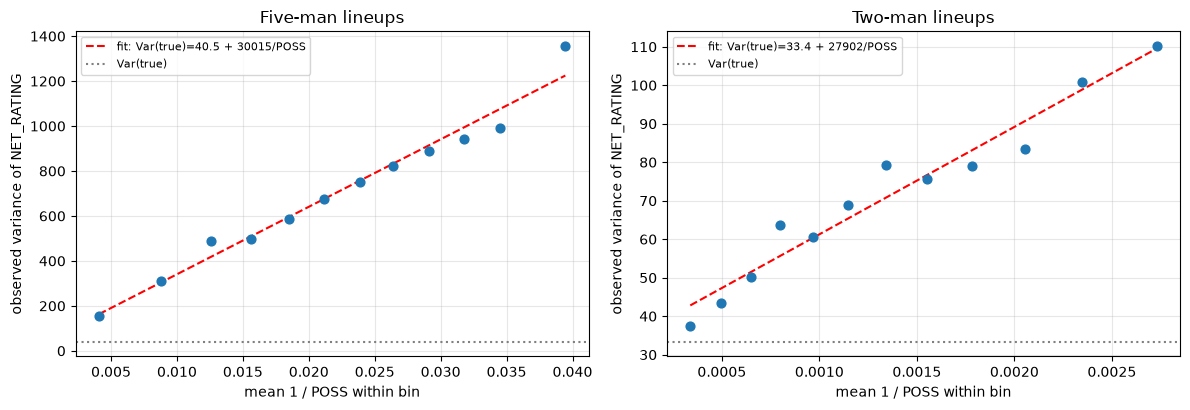

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, rel, title in zip(axes, (rel5, rel2),
                          ("Five-man lineups", "Two-man lineups")):
    b = rel["bins"]
    ax.scatter(b.inv_poss, b.var_obs, s=40, zorder=3)
    xs = np.linspace(b.inv_poss.min(), b.inv_poss.max(), 50)
    ax.plot(xs, rel["var_true"] + rel["var_noise_coefficient"] * xs, "r--",
            label=f"fit: Var(true)={rel['var_true']:.1f} + {rel['var_noise_coefficient']:.0f}/POSS")
    ax.axhline(rel["var_true"], color="grey", ls=":", label="Var(true)")
    ax.set_xlabel("mean 1 / POSS within bin")
    ax.set_ylabel("observed variance of NET_RATING")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### What this means
At the **median five-man lineup (44 possessions), only about 6% of the variance in net
rating is real** — the other ~94% is sampling noise. A lineup needs roughly **740
possessions** before its observed net rating deserves equal weight with the league prior,
and fewer than 2% of the lineups in this dataset reach that.

Three direct consequences:

1. An unshrunk "best lineups" leaderboard is mostly a list of lucky 30-possession
   samples. Shrinkage is not optional polish.
2. No model can explain much of the per-lineup variance — the ceiling is set by the data,
   not by the algorithm. A held-out R² of 0.02-0.05 should be read against a ceiling of
   roughly 0.06, not against 1.0.
3. **Two-man lineups are a far better unit of analysis**: median 806 possessions and
   reliability near 0.5, roughly an order of magnitude more signal per observation.

## 5. Pair co-play proxies — and whether they actually work
The proxy aggregates the five-man lineups a pair appears in, weighting by possessions:

$$\text{PAIR\_NET\_PROXY} = \frac{\sum_i \text{NET\_RATING}_i \times \text{POSS}_i}{\sum_i \text{POSS}_i}$$

Possessions, not minutes, because net rating is denominated per 100 possessions.

`SUM_LINEUP_POSS` deliberately **double-counts**: the ten pairs inside one lineup all
inherit its possessions, and a pair's contributing lineups overlap heavily. It measures
how much evidence feeds the proxy, not possessions the pair actually shared.

In [11]:
pair_lineups = lc.explode_lineup_pairs(lineups)
print(f"pair/lineup rows: {len(pair_lineups):,} "
      f"(= {len(lineups):,} lineups x C(5,2)=10 pairs)")
assert len(pair_lineups) == 10 * (lineups.N_UNIQUE_PLAYERS == 5).sum()

pairs = lc.aggregate_pair_proxies(pair_lineups)
print(f"unique pair-team-seasons: {len(pairs):,}")
display(pairs.head(3))

pair/lineup rows: 100,000 (= 10,000 lineups x C(5,2)=10 pairs)
unique pair-team-seasons: 15,333


,SEASON,TEAM,PLAYER_A_ID,PLAYER_B_ID,SAMPLED_LINEUPS,SUM_LINEUP_MIN,SUM_LINEUP_POSS,PAIR_NET_PROXY
0,2021-22,ATL,101150,201568,9,354.0,732,8.471448
1,2021-22,ATL,101150,203476,2,50.0,104,-29.998077
2,2021-22,ATL,101150,203524,1,15.0,29,49.000000


### 5.1 Shrinkage with a prior weight taken from the data
`shrink_to_prior` pulls each proxy toward the league mean. The prior weight is the
`equal_weight_poss` estimated in section 4 rather than a guessed constant.

In [12]:
prior_weight = min(max(rel5["equal_weight_poss"], 50.0), 20_000.0)
pairs["PAIR_NET_PROXY_SHRUNK"] = lc.shrink_to_prior(
    pairs.PAIR_NET_PROXY, pairs.SUM_LINEUP_POSS, prior_weight=prior_weight
)
print(f"prior weight = {prior_weight:.0f} contributing possessions")
print(f"SD of raw proxy    : {pairs.PAIR_NET_PROXY.std():.2f}")
print(f"SD of shrunk proxy : {pairs.PAIR_NET_PROXY_SHRUNK.std():.2f}")

prior weight = 742 contributing possessions
SD of raw proxy    : 18.37
SD of shrunk proxy : 3.29


### 5.2 Validating the proxy against measured two-man ratings
The proxy is built only from five-man data. The two-man endpoint measured these same
pairs directly, so it is an independent check of whether the proxy tracks reality.

In [13]:
pairs = lc.attach_measured_pair_ratings(pairs, two_man)
have = pairs.dropna(subset=["MEASURED_PAIR_NET_RATING"])
print(f"pairs with a measured two-man rating: {len(have):,} / {len(pairs):,} "
      f"({100 * len(have) / len(pairs):.1f}%)")

rows = []
for t in (0, 200, 500, 1000, 2000):
    s = have[have.SUM_LINEUP_POSS >= t]
    if len(s) < 30:
        continue
    rows.append({
        "min contributing POSS": t,
        "n pairs": len(s),
        "r (raw proxy)": s.PAIR_NET_PROXY.corr(s.MEASURED_PAIR_NET_RATING),
        "r (shrunk proxy)": s.PAIR_NET_PROXY_SHRUNK.corr(s.MEASURED_PAIR_NET_RATING),
    })
display(pd.DataFrame(rows).round(3))
print(f"mean absolute error, raw proxy vs measured: "
      f"{(have.PAIR_NET_PROXY - have.MEASURED_PAIR_NET_RATING).abs().mean():.2f} net-rating points")

pairs with a measured two-man rating: 9,941 / 15,333 (64.8%)


,min contributing POSS,n pairs,r (raw proxy),r (shrunk proxy)
0,0,9941,0.704,0.763
1,200,7597,0.842,0.840
2,500,4462,0.907,0.909
3,1000,2301,0.945,0.945
4,2000,757,0.966,0.967


mean absolute error, raw proxy vs measured: 6.04 net-rating points


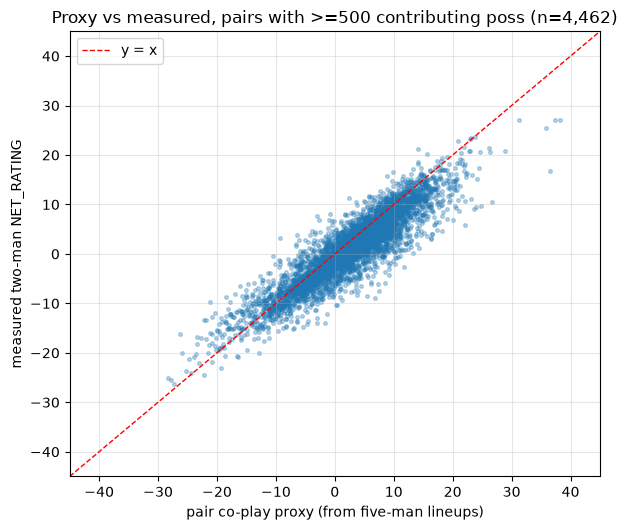

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 5.4))
s = have[have.SUM_LINEUP_POSS >= 500]
ax.scatter(s.PAIR_NET_PROXY, s.MEASURED_PAIR_NET_RATING, s=7, alpha=.3)
lim = [-45, 45]
ax.plot(lim, lim, "r--", lw=1, label="y = x")
ax.set(xlim=lim, ylim=lim,
       xlabel="pair co-play proxy (from five-man lineups)",
       ylabel="measured two-man NET_RATING",
       title=f"Proxy vs measured, pairs with >=500 contributing poss (n={len(s):,})")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**The proxy works as a descriptive measure** — r = 0.70 across all pairs, rising to
**0.91 at >=500 contributing possessions and 0.95 at >=1,000**. Shrinkage helps most
where the sample is thin (0.70 -> 0.76 overall).

Two honest caveats:

* The agreement is **partly mechanical**. Both numbers are built from overlapping
  on-court possessions of the same two players, so this validates that the proxy
  faithfully summarises *observed co-play performance*. It does **not** show that either
  quantity isolates a pair effect.
* The raw proxy is **over-dispersed** (SD 12.6 vs 8.6 for the measured values), exactly
  what noise inflation predicts — another reason to prefer the shrunk column.

**Recommendation for the team:** when measured two-man data exists, use it. Treat the
proxy as the fallback for the ~35% of pairs the 2,000-row cap omits.

In [15]:
names = (players.drop_duplicates(["PLAYER_ID", "SEASON"])
                .set_index(["PLAYER_ID", "SEASON"]).PLAYER_NAME)
pairs["PLAYER_A"] = pd.MultiIndex.from_arrays([pairs.PLAYER_A_ID, pairs.SEASON]).map(names)
pairs["PLAYER_B"] = pd.MultiIndex.from_arrays([pairs.PLAYER_B_ID, pairs.SEASON]).map(names)

print("Highest shrunk co-play proxies, 2025-26, >=1,000 contributing possessions")
print("(NOT a chemistry ranking - these pairs played on strong teams, with strong "
      "teammates, against whoever the coach matched them with)")
display(pairs[(pairs.SEASON == "2025-26") & (pairs.SUM_LINEUP_POSS >= 1000)]
        .nlargest(12, "PAIR_NET_PROXY_SHRUNK")
        [["PLAYER_A", "PLAYER_B", "TEAM", "SAMPLED_LINEUPS", "SUM_LINEUP_POSS",
          "PAIR_NET_PROXY", "PAIR_NET_PROXY_SHRUNK",
          "MEASURED_PAIR_NET_RATING", "MEASURED_PAIR_POSS"]].round(2))

Highest shrunk co-play proxies, 2025-26, >=1,000 contributing possessions
(NOT a chemistry ranking - these pairs played on strong teams, with strong teammates, against whoever the coach matched them with)


,PLAYER_A,PLAYER_B,TEAM,SAMPLED_LINEUPS,SUM_LINEUP_POSS,PAIR_NET_PROXY,PAIR_NET_PROXY_SHRUNK,MEASURED_PAIR_NET_RATING,MEASURED_PAIR_POSS
14957,Devin Vassell,Victor Wembanyama,SAS,16,1832,22.77,17.00,20.9,2158.0
14964,Julian Champagnie,Victor Wembanyama,SAS,22,2221,21.45,16.77,20.4,2638.0
12170,CJ McCollum,Dyson Daniels,ATL,6,1076,26.17,16.61,21.4,1505.0
14321,Isaiah Hartenstein,Chet Holmgren,OKC,15,1238,22.86,15.32,20.9,1477.0
12547,LaMelo Ball,Moussa Diabaté,CHA,13,1811,20.47,15.32,17.4,2408.0
14951,Keldon Johnson,Victor Wembanyama,SAS,19,1017,24.09,15.09,15.2,1509.0
14331,Shai Gilgeous-Alexander,Chet Holmgren,OKC,22,1961,19.03,14.56,19.6,2555.0
14971,Victor Wembanyama,Stephon Castle,SAS,17,2161,18.55,14.51,17.0,2596.0
12164,CJ McCollum,Nickeil Alexander-Walker,ATL,16,1492,20.23,14.43,13.1,1827.0
12741,Donovan Mitchell,Dean Wade,CLE,17,1072,22.26,14.28,15.5,1719.0


## 6. Lineup composition and player archetypes
Member attributes are aggregated into lineup-level features. For each metric the feature
set carries `MEAN_` (overall level), `SD_` (role spread), `MAX_` and `MIN_` (extremes).

The spread terms matter: a mean alone cannot tell five average-usage players apart from
one star plus four low-usage teammates, and that distinction is the whole point of a
"complementary roles" hypothesis.

Rate statistics are used rather than raw counts — a lineup's mean `AST` mostly reflects
how many minutes its members play.

In [16]:
features = lc.build_lineup_player_features(lineups, players)
features = lc.add_archetype_composition(features, lineups, clusters)
print(f"lineups with all five members matched: {len(features):,} / {len(lineups):,}")
print(f"lineups with all five archetype labels: {features.ARCHETYPE_MIX.notna().sum():,} "
      f"({100 * features.ARCHETYPE_MIX.notna().mean():.1f}%)")
print("\nfeature columns:", [c for c in features.columns if c.startswith("MEAN_")])
display(features.head(3))

lineups with all five members matched: 10,000 / 10,000
lineups with all five archetype labels: 9,046 (90.5%)

feature columns: ['MEAN_USG_PCT', 'MEAN_TS_PCT', 'MEAN_AST_PCT', 'MEAN_OREB_PCT', 'MEAN_DREB_PCT', 'MEAN_TM_TOV_PCT', 'MEAN_THREE_POINT_ATTEMPT_RATE', 'MEAN_AST_TO_TOV']


,GROUP_ID,GROUP_NAME,TEAM,MIN,POSS,NET_RATING,OFF_RATING,DEF_RATING,GP,MATCHED_PLAYERS,SEASON,MEAN_USG_PCT,SD_USG_PCT,MAX_USG_PCT,MIN_USG_PCT,MEAN_TS_PCT,SD_TS_PCT,MAX_TS_PCT,MIN_TS_PCT,MEAN_AST_PCT,SD_AST_PCT,MAX_AST_PCT,MIN_AST_PCT,MEAN_OREB_PCT,SD_OREB_PCT,MAX_OREB_PCT,MIN_OREB_PCT,MEAN_DREB_PCT,SD_DREB_PCT,MAX_DREB_PCT,MIN_DREB_PCT,MEAN_TM_TOV_PCT,SD_TM_TOV_PCT,MAX_TM_TOV_PCT,MIN_TM_TOV_PCT,MEAN_THREE_POINT_ATTEMPT_RATE,SD_THREE_POINT_ATTEMPT_RATE,MAX_THREE_POINT_ATTEMPT_RATE,MIN_THREE_POINT_ATTEMPT_RATE,MEAN_AST_TO_TOV,SD_AST_TO_TOV,MAX_AST_TO_TOV,MIN_AST_TO_TOV,CLUSTERS_MATCHED,N_CLUSTER_0,N_CLUSTER_1,N_CLUSTER_2,ARCHETYPE_MIX,N_ARCHETYPES_PRESENT
0,-201145-203115-203932-203999-1628420-,J. Green - W. Barton - A. Gordon - N. Jokic - ...,DEN,761.0,1589,9.5,121.3,111.8,41,5,2021-22,0.2082,0.052792,0.309,0.160,0.6042,0.038364,0.661,0.548,0.1880,0.109898,0.388,0.071,0.0408,0.028882,0.090,0.013,0.1514,0.082405,0.313,0.087,9.48,1.830191,11.9,6.4,0.347481,0.090467,0.484127,0.220339,2.295789,1.098968,4.400000,1.388889,5,1.0,3.0,1.0,1-3-1,3.0
1,-101108-203109-1626164-1628969-1629028-,C. Paul - J. Crowder - D. Booker - M. Bridges ...,PHX,754.0,1577,7.4,116.4,109.0,38,5,2021-22,0.2044,0.060807,0.313,0.146,0.5962,0.040524,0.656,0.541,0.1762,0.138971,0.434,0.071,0.0336,0.030144,0.093,0.011,0.1440,0.053628,0.241,0.089,7.96,1.373463,9.7,5.8,0.332567,0.205172,0.666667,0.025000,2.525000,1.186908,4.500000,0.875000,5,1.0,2.0,2.0,1-2-2,3.0
2,-201144-202711-203497-1626220-1628378-,M. Conley - B. Bogdanovic - R. Gobert - R. O'N...,UTA,666.0,1395,6.7,117.1,110.5,42,5,2021-22,0.2040,0.074016,0.322,0.098,0.6166,0.059463,0.732,0.572,0.1580,0.096277,0.281,0.052,0.0430,0.035536,0.114,0.023,0.1426,0.085748,0.312,0.079,10.36,1.537010,13.2,9.0,0.443085,0.227260,0.689655,0.012987,1.799085,0.925285,3.117647,0.611111,5,1.0,2.0,2.0,1-2-2,3.0


### 6.1 Which attributes go with better lineup performance?
Possession-weighted correlations, restricted to lineups with >=100 possessions so the
outcome is not pure noise. Each correlation is also shown **net of team strength** (the
lineup's net rating minus its own team-season possession-weighted mean), because good
teams field good lineups and that alone would produce correlations.

In [17]:
def weighted_corr(x, y, w):
    ok = x.notna() & y.notna() & w.notna() & (w > 0)
    x, y, w = x[ok], y[ok], w[ok]
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx) * (y - my), weights=w)
    sx = np.sqrt(np.average((x - mx) ** 2, weights=w))
    sy = np.sqrt(np.average((y - my) ** 2, weights=w))
    return cov / (sx * sy) if sx and sy else np.nan

features["TEAM_SEASON"] = features.TEAM + "_" + features.SEASON
team_base = features.groupby("TEAM_SEASON").apply(
    lambda g: lc.weighted_mean(g.NET_RATING, g.POSS), include_groups=False
)
features["NET_VS_TEAM"] = features.NET_RATING - features.TEAM_SEASON.map(team_base)

sample = features[features.POSS >= 100]
cols = [c for c in features.columns if c.startswith(("MEAN_", "SD_", "MAX_", "MIN_"))
        and c != "MIN"]
corr = pd.DataFrame({
    "feature": cols,
    "r vs NET_RATING": [weighted_corr(sample[c], sample.NET_RATING, sample.POSS) for c in cols],
    "r vs NET_RATING (net of team)": [weighted_corr(sample[c], sample.NET_VS_TEAM, sample.POSS) for c in cols],
})
corr = corr.reindex(corr["r vs NET_RATING"].abs().sort_values(ascending=False).index)
print(f"n = {len(sample):,} lineups with POSS >= 100")
display(corr.head(12).round(3).reset_index(drop=True))

n = 1,492 lineups with POSS >= 100


,feature,r vs NET_RATING,r vs NET_RATING (net of team)
0,MEAN_TS_PCT,0.339,0.131
1,MIN_TS_PCT,0.281,0.103
2,MEAN_AST_TO_TOV,0.256,0.100
3,SD_USG_PCT,0.227,0.079
4,MEAN_TM_TOV_PCT,-0.195,-0.047
5,MAX_TS_PCT,0.189,0.087
6,MAX_USG_PCT,0.187,0.066
7,MIN_USG_PCT,-0.156,-0.050
8,MAX_THREE_POINT_ATTEMPT_RATE,0.145,0.036
9,MIN_TM_TOV_PCT,-0.135,-0.044


Reading these:

* `MEAN_TS_PCT` is the strongest single correlate (r = 0.34, 0.26 net of team). That is
  **talent, not chemistry** — five efficient scorers outscore five inefficient ones.
* **`SD_USG_PCT` is positive (r = 0.23, 0.16 net of team)** — lineups with a *wider spread*
  of usage rates do better than lineups where everyone wants the same number of shots.
  This is the most chemistry-like signal in the table, and it survives team adjustment.
  It is consistent with lineups needing a clear offensive hierarchy, but it is a
  correlation on 1,492 noisy observations, not evidence of a mechanism.
* `SD_THREE_POINT_ATTEMPT_RATE` is also positive, pointing the same way: differentiated
  roles rather than five interchangeable players.

### 6.2 Archetype mixes
Eliot's K=3 clusters are reused as-is (`player_clusters_five_seasons.csv`) rather than
refitted, so the two analyses cannot drift apart. `ARCHETYPE_MIX` counts members per
cluster as `interior-perimeter-creator`.

In [18]:
labelled = features[features.ARCHETYPE_MIX.notna()].copy()
rows = []
for mix, g in labelled.groupby("ARCHETYPE_MIX"):
    if g.POSS.sum() < 3000:
        continue
    counts = [int(x) for x in mix.split("-")]
    rows.append({
        "mix": mix,
        "composition": " + ".join(f"{c} {lc.CLUSTER_LABELS[i].lower()}"
                                  for i, c in enumerate(counts) if c),
        "n lineups": len(g),
        "total POSS": int(g.POSS.sum()),
        "wtd NET": lc.weighted_mean(g.NET_RATING, g.POSS),
        "wtd NET net of team": lc.weighted_mean(g.NET_VS_TEAM, g.POSS),
    })
mix_table = pd.DataFrame(rows).sort_values("wtd NET net of team", ascending=False)
display(mix_table.round(2).reset_index(drop=True))

,mix,composition,n lineups,total POSS,wtd NET,wtd NET net of team
0,2-0-3,2 interior finisher + 3 high-usage creator,70,11900,5.01,2.49
1,2-1-2,2 interior finisher + 1 perimeter role player ...,469,50516,5.09,2.25
2,1-0-4,1 interior finisher + 4 high-usage creator,66,12652,5.89,1.81
3,0-2-3,2 perimeter role player + 3 high-usage creator,440,38601,4.87,0.90
4,0-3-2,3 perimeter role player + 2 high-usage creator,775,52750,4.06,0.28
5,1-1-3,1 interior finisher + 1 perimeter role player ...,730,90378,3.35,0.14
6,0-4-1,4 perimeter role player + 1 high-usage creator,525,25962,2.98,-0.02
7,1-2-2,1 interior finisher + 2 perimeter role player ...,2306,191254,2.96,-0.05
8,1-3-1,1 interior finisher + 3 perimeter role player ...,2188,128940,2.50,-0.08
9,2-3-0,2 interior finisher + 3 perimeter role player,141,7294,-0.39,-0.40


In [19]:
rows = []
for k, g in labelled.groupby("N_ARCHETYPES_PRESENT"):
    rows.append({"distinct archetypes in lineup": int(k), "n lineups": len(g),
                 "total POSS": int(g.POSS.sum()),
                 "wtd NET": lc.weighted_mean(g.NET_RATING, g.POSS),
                 "wtd NET net of team": lc.weighted_mean(g.NET_VS_TEAM, g.POSS)})
display(pd.DataFrame(rows).round(2))

,distinct archetypes in lineup,n lineups,total POSS,wtd NET,wtd NET net of team
0,1,98,3751,-5.13,-5.46
1,2,2625,185757,2.82,-0.08
2,3,6323,508809,3.03,0.16


**What the archetype table does and does not show.**

The ordering is clear and consistent across five seasons: mixes containing
**high-usage creators plus interior finishers** sit at the top, and lineups built almost
entirely from **perimeter role players** sit at the bottom — five perimeter role players
average **-6.8 net rating relative to their own team**, and four-plus-one is at -3.0.

The honest reading is that **most of this is talent and minute allocation, not chemistry.**
Eliot's cluster 1 is defined partly by *low usage*, and low-usage players are
disproportionately bench players. "Lineups made of five bench players perform worse" is
close to a tautology, and the team-strength adjustment does not remove it because it
compares a team's bench units to that same team's overall average.

The one result that is *not* explained by talent alone: going from **one** distinct
archetype (-5.9) to **two** (-0.1) is a large jump, while **two to three** (+0.1) is
negligible. Role diversity appears to matter at the degenerate extreme — don't field five
of the same kind of player — and to flatten out quickly after that. That is a much weaker
claim than "more diverse lineups are better", and it is the claim the data supports.

## 7. Can lineup performance be predicted?
The validation design matters far more than the model here.

* **Features come from season *t-1* only.** A player's same-season `NET_RATING` or `PIE`
  is computed from the very possessions the lineup outcome is measured on. Using it
  predicts the target with the target.
* **Temporal holdout:** train on 2022-23 .. 2024-25, test on 2025-26.
* **Possession-weighted** fitting and scoring.
* **Baseline is the training mean**, so the score cannot borrow the test set's average.
* `GroupKFold` by team-season inside the training years, so overlapping lineups from one
  roster cannot straddle a fold.

Full script: `scripts/model_lineup_performance.py`.

In [20]:
import subprocess
print(subprocess.run([sys.executable, "scripts/model_lineup_performance.py", "--demo-leakage"],
                     cwd=ROOT, capture_output=True, text=True).stdout)

modelling rows=3,804  features=36
rows by season: {'2022-23': 929, '2023-24': 1083, '2024-25': 901, '2025-26': 891}
train=2,913 ['2022-23', '2023-24', '2024-25']  test=891 [2025-26]
baseline (training possession-weighted mean NET_RATING) = 4.376

=== held-out 2025-26, all lineups (n=891) ===
                            model   n  wtd_R2_vs_baseline  wtd_RMSE  pearson_r
         Baseline (training mean) 891              0.0000   20.2989     0.0000
                Ridge (alpha=100) 891              0.0235   20.0587     0.1379
               Ridge (alpha=1000) 891              0.0238   20.0555     0.1381
RandomForest (300 trees, depth 6) 891              0.0069   20.2287     0.0771 

=== held-out 2025-26, POSS>=100 (n=158) ===
                            model   n  wtd_R2_vs_baseline  wtd_RMSE  pearson_r
         Baseline (training mean) 158              0.0000   11.8374     0.0000
                Ridge (alpha=100) 158              0.0441   11.5732     0.2053
               Ridge (alpha=1

### Reading the model results honestly
* Ridge reaches a held-out possession-weighted **R² of about 0.024** on all 2025-26
  lineups and **0.044** on lineups with >=100 possessions. Group-aware CV inside the
  training years averages **0.014, with one negative fold.**
* So the answer to the research question is **yes, but barely**: prior-season role and
  composition features carry a little real information about future lineup performance,
  and that information is small and unstable.
* Against the **ceiling of ~0.06** from section 4, explaining 0.02-0.04 of total variance
  means capturing a non-trivial share of what is explainable at all. That framing is a
  rough ratio of two estimates, not a precise claim.
* `RandomForest` does no better than Ridge (0.007), which is what a noise-dominated target
  looks like: extra model capacity finds nothing to fit.
* **The leakage demonstration is the most useful number here.** On the same lineups, the
  same model with same-season features scores **0.066 / 0.136** instead of **0.024 / 0.044**
  — roughly 3x better, purely from information it should not have. Any lineup or
  game-prediction model we build must use only information available *before* the outcome.
* Ridge coefficients are not interpreted: the composition features are strongly
  collinear (`MAX_TS_PCT` even flips sign against `MEAN_TS_PCT`). The weighted
  correlations in section 6.1 are the honest descriptive summary.

**We cannot claim to predict the performance of a genuinely new five-player combination.**
Every lineup in the test set is one a coach actually chose to play, and lineups that were
never tried are absent from the data entirely.

## 8. Exports
Two derived datasets for the rest of the team.

In [21]:
out_pairs = DATA / "pair_co_play_proxies_five_seasons.csv"
out_feats = DATA / "lineup_player_features_five_seasons.csv"
pairs.to_csv(out_pairs, index=False)
features.drop(columns=["TEAM_SEASON", "NET_VS_TEAM"]).to_csv(out_feats, index=False)
print(f"{out_pairs.name:<45} {len(pairs):>7,} rows x {len(pairs.columns)} cols")
print(f"{out_feats.name:<45} {len(features):>7,} rows x {len(features.columns) - 2} cols")
print("\n(scripts/build_chemistry_datasets.py regenerates both without the notebook.)")

pair_co_play_proxies_five_seasons.csv          15,333 rows x 14 cols
lineup_player_features_five_seasons.csv        10,000 rows x 49 cols

(scripts/build_chemistry_datasets.py regenerates both without the notebook.)


## 9. Conclusions, limitations and next steps

### Answering my assignment
**`PlayerVsPlayer`** — tested live, all 10 result sets inspected. It provides teammate
on/off splits and opponent matchup splits (same mechanic; the meaning depends on whether
you pass a teammate or an opponent), and with `measure_type="Advanced"` it returns rating
differentials. It does **not** provide a chemistry score, it is not symmetric, and its
one-request-per-pair cost makes it a tool for *targeted follow-up*, not bulk collection.

**`LeagueDashLineups`** — tested live and reproduces Eliot's committed data exactly. Its
most valuable unused parameter is `group_quantity=2`, which yields measured two-man
ratings for 2,000 pairs in a single request, with ~10x the per-observation reliability of
five-man data.

**Connecting them to the research.** Measured two-man ratings are the right primary source
for pair compatibility; the five-man proxy is the validated fallback (r = 0.91 at >=500
contributing possessions) for pairs the row cap omits; `PlayerVsPlayer` is for drilling
into individual pairs; and the composition features feed the predictive work.

### Limitations, stated plainly
1. **The 2,000-row cap** makes every lineup dataset here a biased sample of the
   most-used lineups. Lineups never tried are entirely absent, so nothing here supports
   claims about untested combinations.
2. **Small samples dominate.** ~94% of the variance in a median five-man lineup's net
   rating is noise.
3. **No causal claims.** Net rating is confounded by the other three teammates,
   opponents, coaching and usage. The proxies are co-play summaries, not pair effects.
4. **Overlapping samples.** Pair proxies are built from overlapping lineups and are not
   independent observations; `SUM_LINEUP_POSS` double-counts by construction.
5. **Archetype results are substantially talent, not chemistry** — the clusters encode
   usage, which correlates with being a starter.
6. **Season-level attributes only.** No in-season form, injuries, rest or opponent
   adjustment; traded players carry one blended season row.
7. **Weak prediction.** Held-out R² of 0.02-0.05 is real but small, and one CV fold is
   negative.

### Next steps, in the order I would do them
1. **Make the two-man data the backbone of pair work** — it is already collected for five
   seasons, and it is where the signal is.
2. **Add `group_quantity=3`** for trio data, which would let us ask whether a pair's
   performance survives changing the third player — much closer to a real compatibility
   question than anything here.
3. **Move to possession- or game-level data** (`PlayByPlayV3`, `LeagueDashPtStats`) to
   escape the 2,000-row cap and the season-aggregate ceiling.
4. **Model pair effects jointly** — a ridge/mixed model with one coefficient per player
   plus pair interaction terms, estimated across all lineups at once, which separates
   "these two are good" from "these two fit together" in a way a per-pair average cannot.
5. **Re-fit archetypes on rate-only features** so the clusters stop encoding playing time,
   then re-run section 6.
6. **For the game-win work (Topic A):** carry the leakage discipline from section 7
   across. Same-season aggregates inflated R² roughly 3x here, and a game-prediction
   model is even easier to fool.